# Análisis exploratorio de MovieLens 32M
**Informe de datos · Épica 1 · US1.5 t1**

| | |
|---|---|
| **Objetivo** | Caracterizar las calificaciones, su calidad y la dispersión de la matriz usuario × película antes de entrenar recomendadores. |
| **Datos** | MovieLens 32M (GroupLens), después de la validación (US1.3 t1) y de la limpieza k-core (US1.3 t2) del pipeline DVC. |
| **Reproducción** | `make pipeline` y luego `make eda` (ejecuta este notebook y guarda las figuras). |
| **Relación con el dashboard** | Usa las mismas consultas (`src/movielens/eda.py`). El dashboard (`make dashboard`) agrega filtros interactivos. |

Las cifras del texto corresponden a la ejecución del 2026-11-25. Las figuras y las tablas se recalculan cada vez que se ejecuta el notebook.

## Resumen ejecutivo

1. **Los datos son confiables.** Los 37 controles de calidad del pipeline pasan: 12 sobre los archivos (integridad y esquema) y 25 sobre el contenido. No hay valores faltantes, notas fuera de escala, ratings repetidos ni IDs de usuario o película inexistentes (Tabla 2).
2. **La escala real es de 0,5 a 5,0 en medias estrellas.** Las medias estrellas existen desde 2003 y desde 2004 representan alrededor del 40% de los ratings de cada año (Figura 2). La nota más frecuente es 4,0 (26,1%) y la media es 3,54.
3. **La actividad está muy concentrada.** El 10% de las películas más populares reúne el 95,7% de los ratings (Gini 0,95). Entre usuarios la desigualdad es moderada (Gini 0,59), porque MovieLens solo incluye usuarios con al menos 20 ratings (Figuras 4 y 5).
4. **Las películas populares reciben mejores notas.** Hay un sesgo de popularidad (ρ de Spearman 0,25): las películas con más de 10.000 ratings promedian 3,63, frente a 3,08 en las que tienen entre 10 y 99 (Figura 6). Ocurre algo parecido con los clásicos: las películas de los años 40 y 50 promedian 3,85-3,86, frente a 3,48 en las de los 90 (Figura 10).
5. **La matriz es extremadamente dispersa.** Su densidad es del 0,189% y se concentra en el bloque de usuarios activos × películas populares, que llega al 43% (Figura 11).
6. **El k-core con k = 10 es una limpieza barata.** Conserva el 99,5% de los ratings y todos los usuarios menos uno, pero solo el 37,9% de las películas, y eleva la densidad a 0,496%. Con k = 30 se pierde el 17% de los usuarios (Figuras 12 y 13).

### Contenido
1. Datos y método
2. Calificaciones
3. Actividad y popularidad
4. Dinámica temporal
5. Contenido: géneros y década de estreno
6. Dispersión de la matriz y efecto del k-core
7. Conclusiones e implicancias para el modelado
8. Limitaciones
9. Anexo: reproducibilidad

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
import os
os.environ.setdefault('OPENBLAS_NUM_THREADS', '4')   # servidor del lab con `ulimit -v` (D-07)

import numpy as np
import pandas as pd
import yaml

from movielens import eda, report as R
from movielens.config import CHECKS_REPORT, INTEGRITY_REPORT, KCORE_SWEEP, ROOT, load_params, resolve
from movielens.reporting import load_report

params = load_params()
K = params['data']['min_ratings']                       # umbral del EDA (US1.3 t2)
validated = eda.open_db(resolve(params['data']['interim_dir']))    # salida de US1.3 t1
clean = eda.open_db(resolve(params['data']['processed_dir']))      # salida de US1.3 t2 (k-core)

kv, kc = eda.kpis(validated), eda.kpis(clean)
users, movies = eda.entity_stats(validated, by='userId'), eda.entity_stats(validated, by='movieId')
users_c, movies_c = eda.entity_stats(clean, by='userId'), eda.entity_stats(clean, by='movieId')

## 1. Datos y método

**Fuente.** MovieLens 32M contiene ratings de 0,5 a 5,0 estrellas con fecha y hora, el catálogo de películas con sus géneros, tags y enlaces a IMDb/TMDb. Cada usuario del dataset tiene al menos 20 ratings.

**Pipeline (DVC).** El análisis no lee los CSV directamente, sino las capas que produce el pipeline:

| Etapa | Qué hace | Capa usada en este informe |
|---|---|---|
| `ingest` | Verifica el MD5 de los CSV y los convierte a Parquet con un esquema estricto | — |
| `validate` | Ejecuta los controles de calidad y detiene el pipeline si falla uno bloqueante | **Validado** (`data/interim`) |
| `clean` | Elimina usuarios y películas con menos de `data.min_ratings` ratings, repitiendo hasta que todos cumplen (k-core) | **Limpio** (`data/processed`) |

**Convenciones.** Salvo que se indique otra cosa, las figuras usan el dataset *validado*, que contiene todos los ratings que pasaron los controles. La sección 6 compara el validado con el *limpio*. Los intervalos de confianza son normales al 95%. Los números se escriben con coma decimal y punto de miles.

In [2]:
lock = yaml.safe_load(open(ROOT / 'dvc.lock'))
data_hash = next(o['md5'] for o in lock['stages']['clean']['outs'] if o['path'] == 'data/processed')
t0, t1 = validated.execute("SELECT min(make_timestamp(timestamp * 1000000))::DATE, "
                           "max(make_timestamp(timestamp * 1000000))::DATE FROM ratings").fetchone()
n_catalog = validated.execute('SELECT count(*) FROM movies').fetchone()[0]
print(f'Período de los ratings: {t0} a {t1} · Catálogo: {eda.fmt_int(n_catalog)} películas · '
      f'Versión de los datos limpios (dvc.lock): {data_hash[:12]}')

def fmt_row(name, a, b, kind):
    f = {'int': eda.fmt_int, 'dec': lambda v: eda.fmt_num(v, 2), 'pct': lambda v: eda.fmt_pct(v, 3)}[kind]
    kept = eda.fmt_pct(100 * b / a, 2) if kind == 'int' else '—'
    return {'Indicador': name, 'Validado': f(a), f'Limpio (k-core {K})': f(b), 'Conservado': kept}

R.table(pd.DataFrame([
    fmt_row('Ratings', kv['ratings'], kc['ratings'], 'int'),
    fmt_row('Usuarios', kv['users'], kc['users'], 'int'),
    fmt_row('Películas con ratings', kv['movies'], kc['movies'], 'int'),
    fmt_row('Nota media', kv['mean_rating'], kc['mean_rating'], 'dec'),
    fmt_row('Nota mediana', kv['median_rating'], kc['median_rating'], 'dec'),
    fmt_row('Densidad de la matriz', kv['density_pct'], kc['density_pct'], 'pct'),
]), 'Tabla 1. Descripción del dataset validado y del limpio')

Período de los ratings: 1995-01-09 a 2023-10-13 · Catálogo: 87.585 películas · Versión de los datos limpios (dvc.lock): 40e3a792e5ae


Indicador,Validado,Limpio (k-core 10),Conservado
Ratings,32.000.204,31.842.696,"99,51%"
Usuarios,200.948,200.947,"100,00%"
Películas con ratings,84.432,31.961,"37,85%"
Nota media,"3,54","3,54",—
Nota mediana,"3,50","3,50",—
Densidad de la matriz,"0,189%","0,496%",—


### 1.1 Controles de calidad (US1.3 t1)
La Tabla 2 resume el último reporte del pipeline (`reports/quality/*.json`). Si un control **bloqueante** falla, DVC detiene el pipeline y no se generan datos limpios. Un **aviso** queda registrado, pero no detiene el pipeline.

In [3]:
checks = load_report(INTEGRITY_REPORT)['checks'] + load_report(CHECKS_REPORT)['checks']
t2 = pd.DataFrame([{
    'Control': c['name'],
    'Regla': f"MD5 = {c['expected'][:10]}…" if c['id'].endswith('_md5') else c['expected'],
    'Severidad': 'Bloqueante' if c['severity'] == 'blocking' else 'Aviso',
    'Resultado': '✔ pasa' if c['passed'] else '✘ falla',
    'Filas que incumplen': eda.fmt_int(c['n_failed']),
} for c in checks])
print(f"{(t2['Resultado'] == '✔ pasa').sum()} de {len(t2)} controles pasan")
R.table(t2, 'Tabla 2. Controles de calidad aplicados por el pipeline', left=['Control', 'Regla', 'Severidad', 'Resultado'])

37 de 37 controles pasan


Control,Regla,Severidad,Resultado,Filas que incumplen
Existe ratings.csv,presente en ml-32m/,Bloqueante,✔ pasa,0
MD5 de ratings.csv coincide con checksums.txt,MD5 = cf12b74f9a…,Bloqueante,✔ pasa,0
Existe movies.csv,presente en ml-32m/,Bloqueante,✔ pasa,0
MD5 de movies.csv coincide con checksums.txt,MD5 = 0df90835c1…,Bloqueante,✔ pasa,0
Existe tags.csv,presente en ml-32m/,Bloqueante,✔ pasa,0
MD5 de tags.csv coincide con checksums.txt,MD5 = 963bf4fa4d…,Bloqueante,✔ pasa,0
Existe links.csv,presente en ml-32m/,Bloqueante,✔ pasa,0
MD5 de links.csv coincide con checksums.txt,MD5 = 8f033867bc…,Bloqueante,✔ pasa,0
ratings.csv se parsea con el esquema esperado,"userId:int32, movieId:int32, rating:float, timestamp:int64",Bloqueante,✔ pasa,0
movies.csv se parsea con el esquema esperado,"movieId:int32, title:string, genres:string",Bloqueante,✔ pasa,0


## 2. Calificaciones

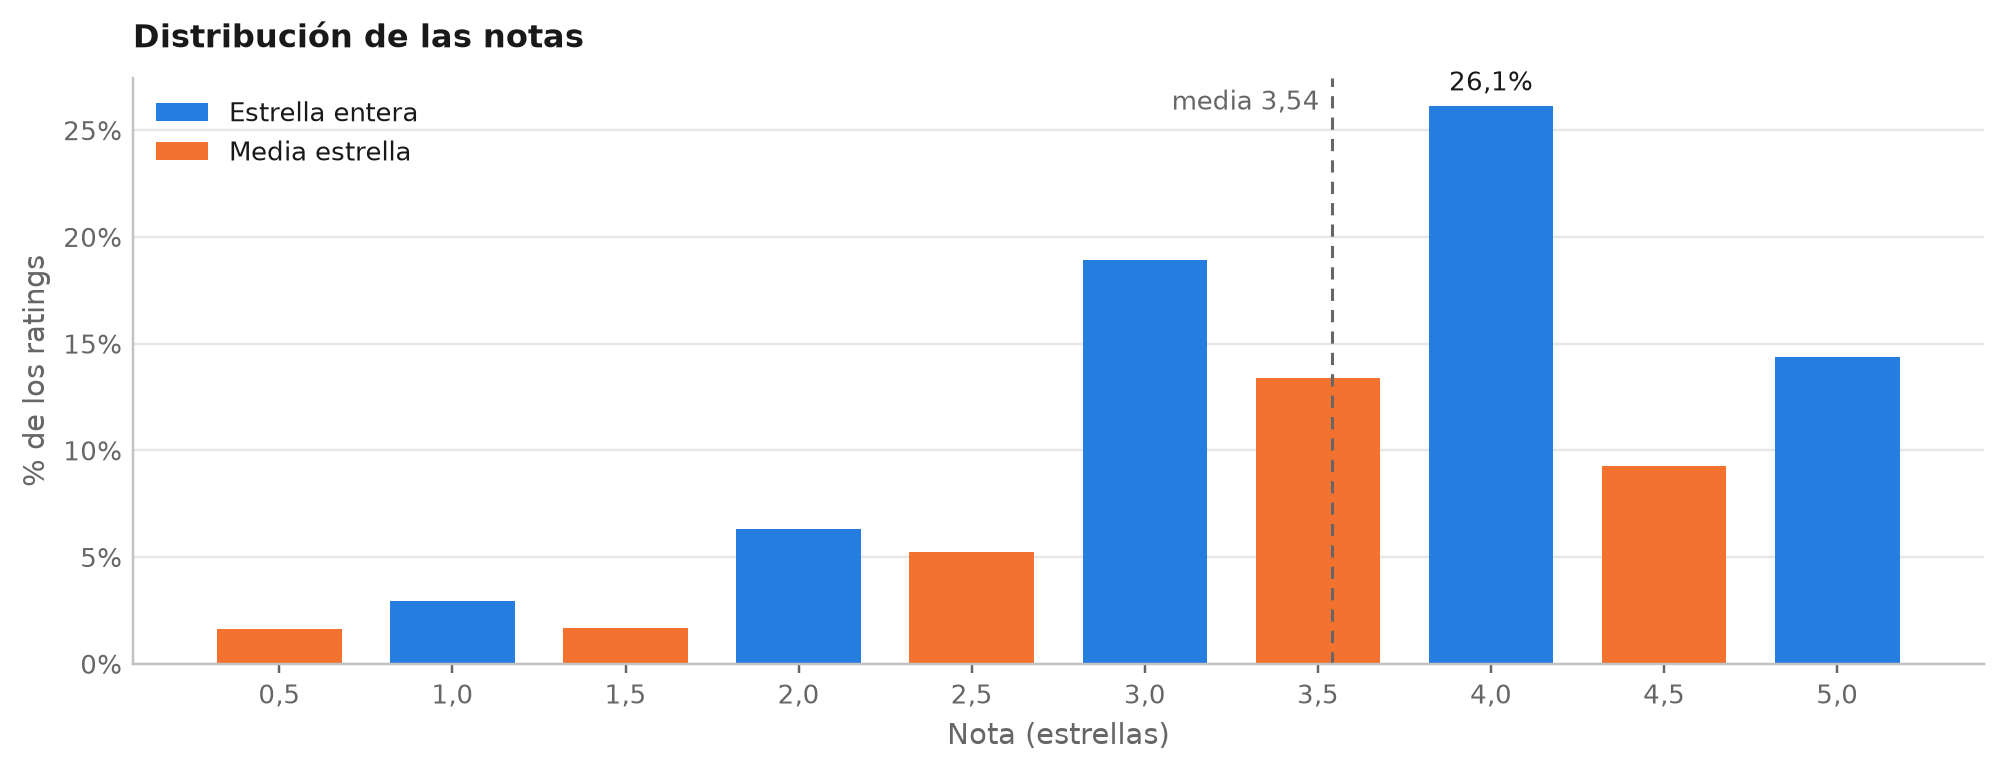

In [4]:
dist = eda.rating_distribution(validated)
R.fig_rating_distribution(dist, kv['mean_rating'])

**Figura 1.** Distribución de las notas en el dataset validado, en porcentaje sobre el total de ratings. Las barras naranjas son medias estrellas.

**Lectura.** La distribución es asimétrica hacia las notas altas: la moda es 4,0 (26,1%), la media 3,54 y la mediana 3,5. Las medias estrellas suman el 31,3% de los ratings. La nota mínima del sistema es 0,5 y la usa el 1,6% de los ratings, por lo que una regla de validación literal de «1 a 5» descartaría 525.132 ratings legítimos (decisión D-01).

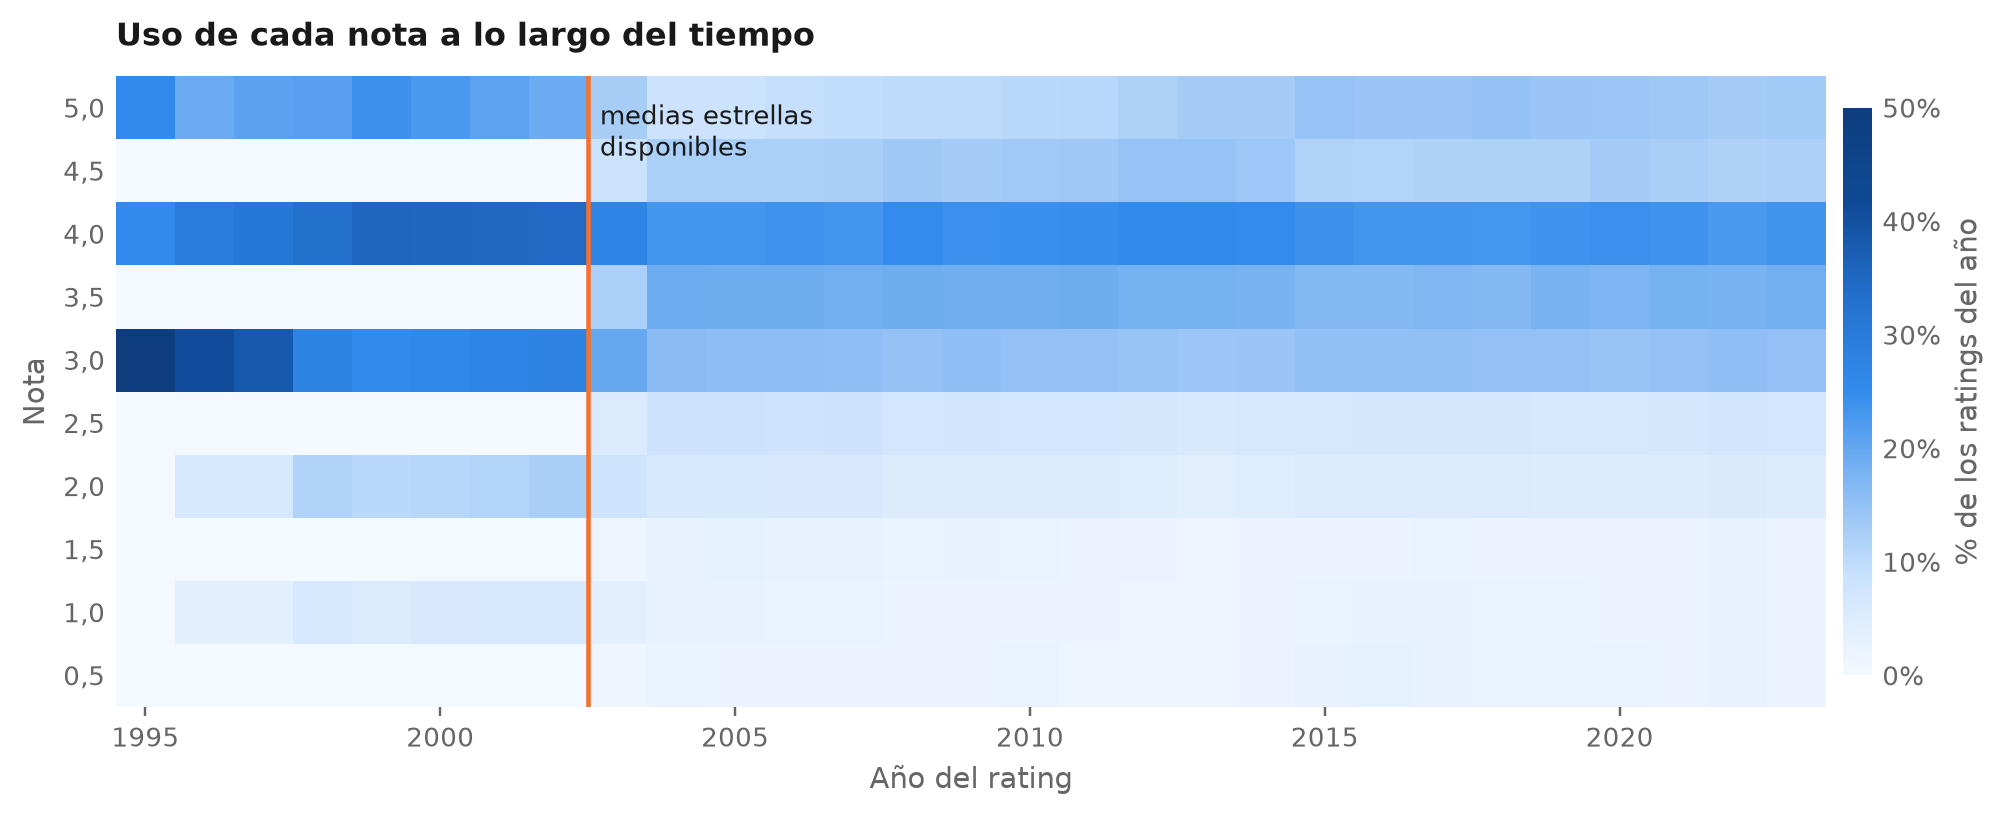

In [5]:
R.fig_rating_share_by_year(eda.rating_share_by_year(validated))

**Figura 2.** Porcentaje de los ratings de cada año que corresponde a cada nota. Las columnas suman 100%. La columna de 1995 se basa en solo 4 ratings.

**Lectura.** Antes de 2003 solo existían estrellas enteras, y 3,0 y 4,0 concentraban la mayoría de los ratings. Desde 2003 las medias estrellas absorben parte de esas notas y se estabilizan en torno al 40% de cada año. **Implicancia:** en los modelos con ratings explícitos conviene tratar la escala como continua y no como 10 clases, y considerar el año como posible fuente de deriva.

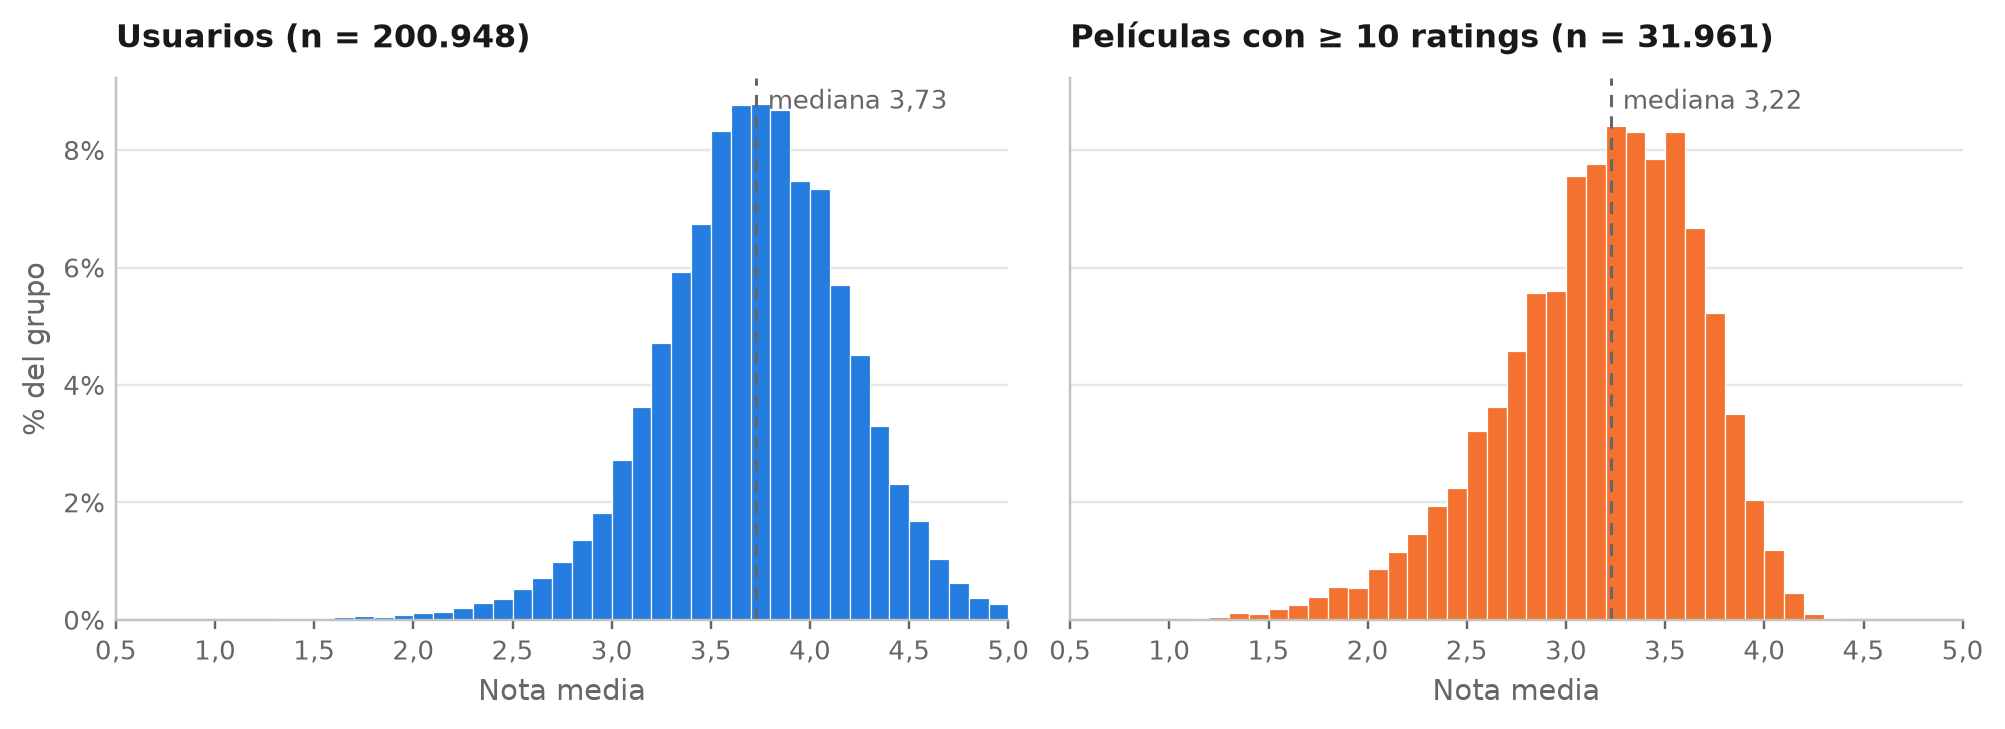

In [6]:
R.fig_mean_rating_histograms(users, movies, K)

**Figura 3.** Distribución de la nota media por usuario (izquierda) y por película con al menos k ratings (derecha). La línea discontinua marca la mediana.

**Lectura.** Los usuarios son generosos: la mitad promedia más de 3,73, y el 80% central está entre 3,11 y 4,29. Las películas, en cambio, tienen una mediana de 3,22. La diferencia se explica porque los usuarios ven y califican sobre todo películas buenas y populares (Figura 6). **Implicancia:** cualquier modelo de ratings necesita sesgos por usuario y por película (*baseline* μ + b<sub>u</sub> + b<sub>i</sub>) antes de modelar interacciones.

## 3. Actividad y popularidad

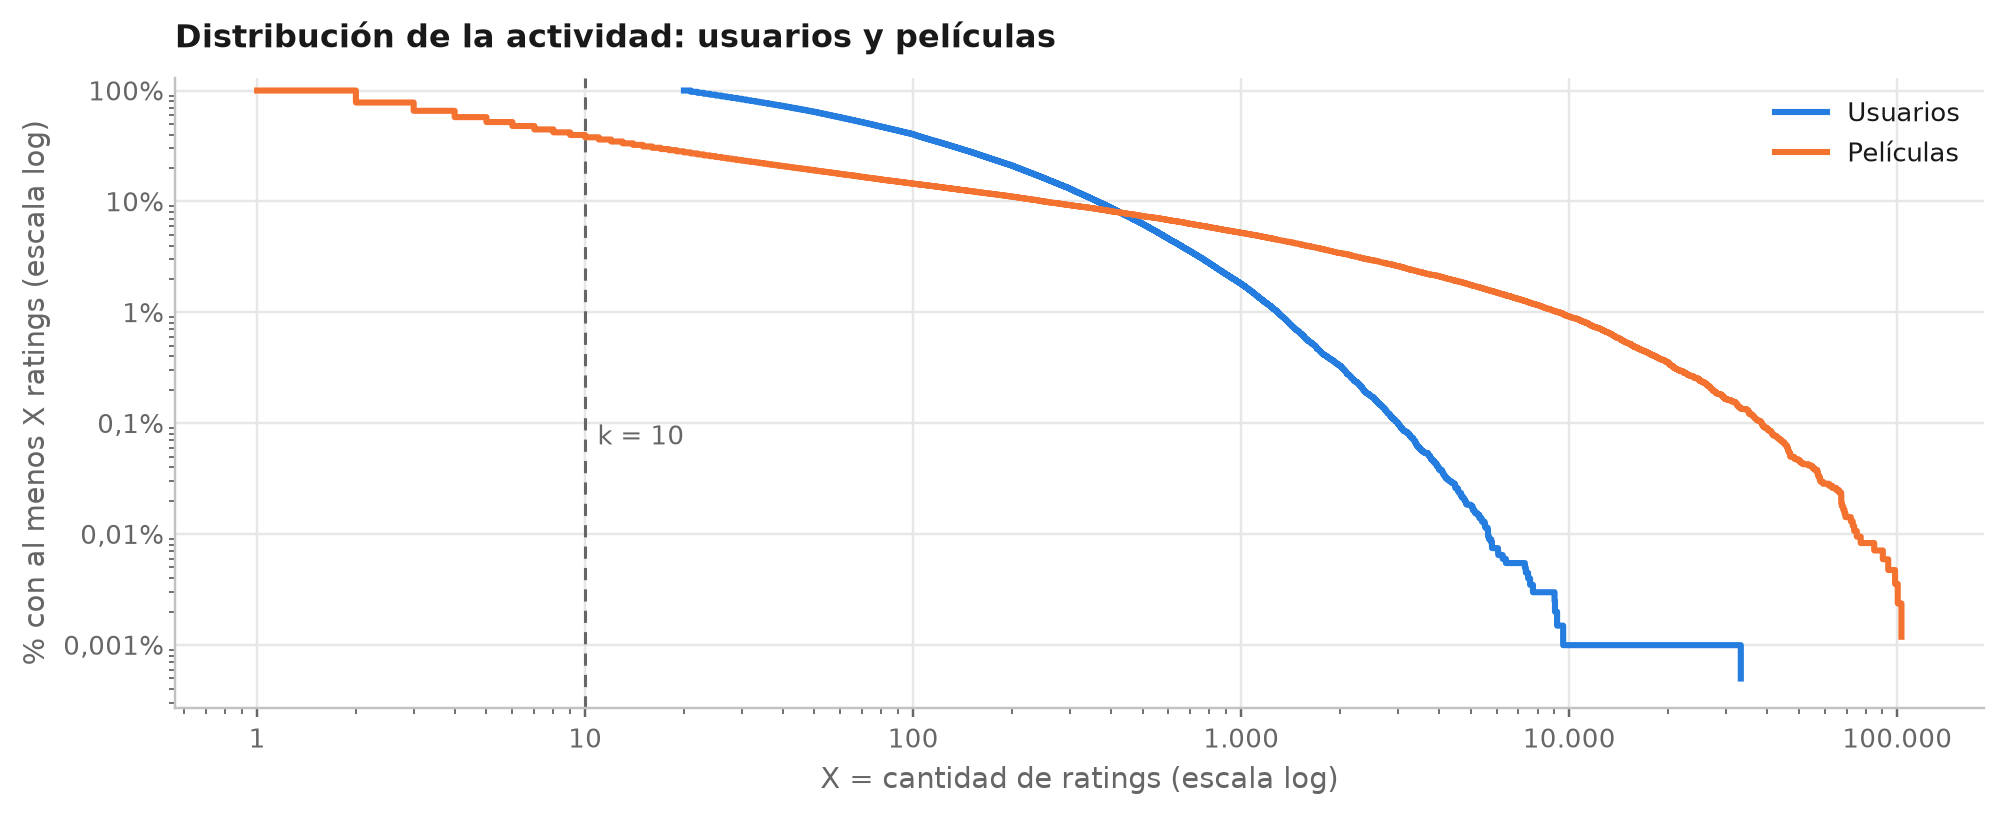

In [7]:
R.fig_activity_ccdf(users['n'], movies['n'], K)

**Figura 4.** Función de supervivencia (CCDF) del número de ratings por usuario y por película, en escala log-log. Cada punto indica qué porcentaje de usuarios o películas tiene al menos X ratings. La línea discontinua marca el umbral k del k-core.

**Lectura.** Ningún usuario tiene menos de 20 ratings, porque es una condición de MovieLens. La mediana es de 73 ratings y el usuario más activo tiene 33.332. Entre las películas, la mediana es de solo 5 ratings, el 62,1% tiene menos de 10 y 18.607 tienen exactamente uno. Las dos distribuciones tienen colas largas: unos pocos usuarios y películas acumulan miles de ratings, mientras que la mayoría tiene muy pocos.

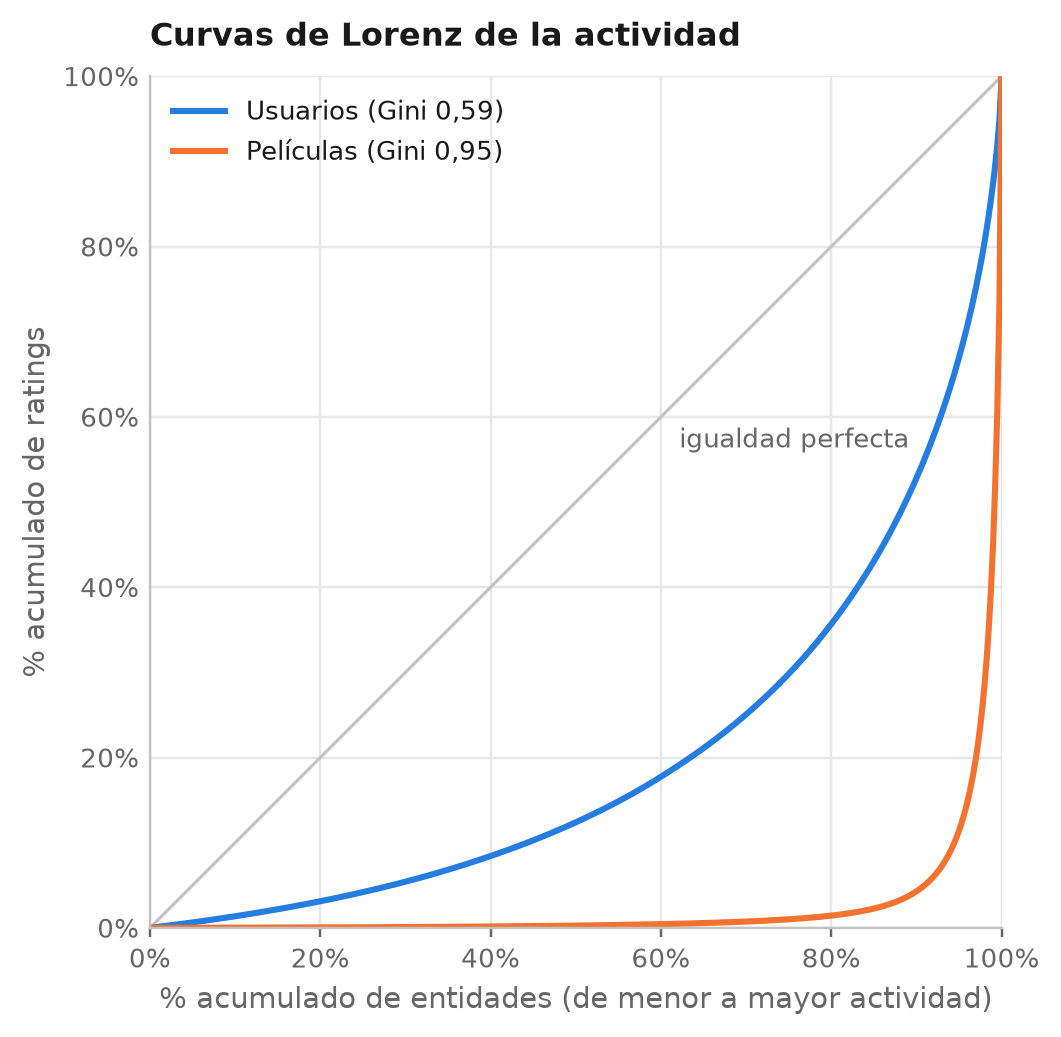

In [8]:
R.fig_concentration(users['n'], movies['n'])

**Figura 5.** Curvas de Lorenz de la actividad. Las entidades se ordenan de menor a mayor actividad. Cuanto más se aleja una curva de la diagonal, más concentrados están los ratings.

**Lectura.** La concentración es mucho mayor en las películas (Gini 0,95) que en los usuarios (Gini 0,59). El 10% de las películas más populares reúne el 95,7% de los ratings, mientras que el 10% de los usuarios más activos reúne el 47,2%. **Implicancia:** un recomendador que solo optimice precisión tenderá a recomendar el mismo grupo reducido de películas. Conviene medir también la cobertura del catálogo y la novedad.

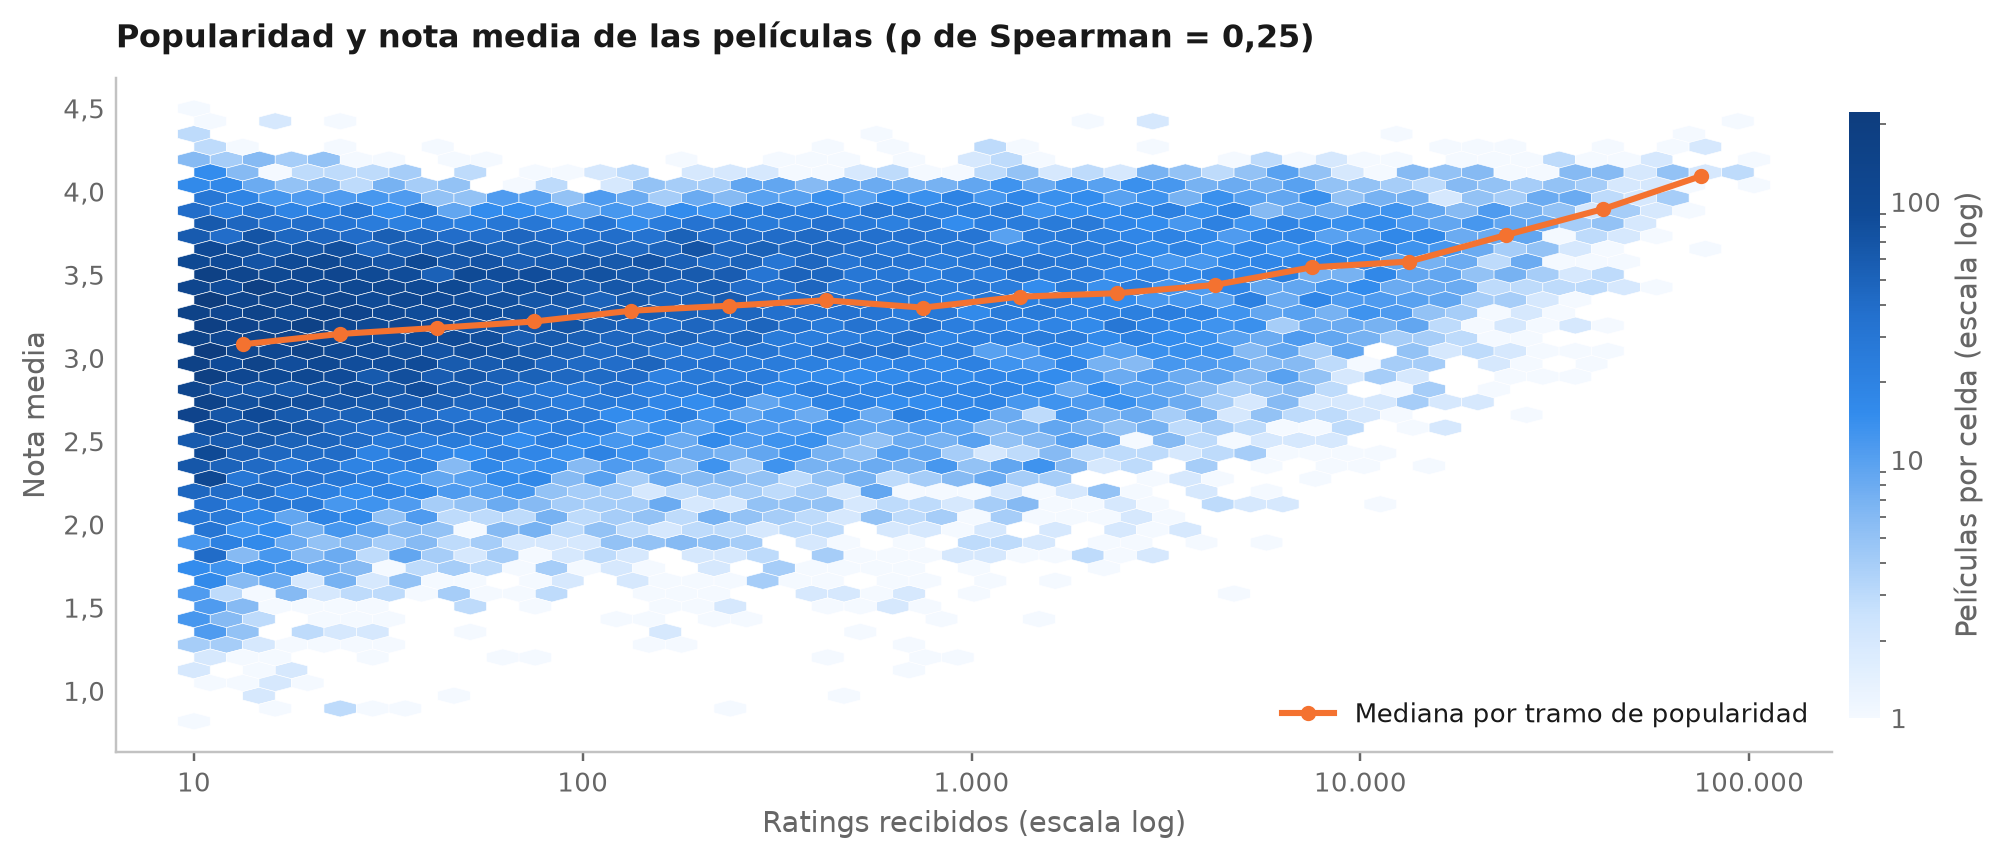

In [9]:
R.fig_popularity_vs_rating(movies, K)

**Figura 6.** Nota media frente al número de ratings de cada película con al menos k ratings. El color indica cuántas películas hay en cada celda. La línea naranja es la mediana por tramo de popularidad.

**Lectura.** La relación es positiva y monótona (ρ de Spearman 0,25). La nota media sube de 3,08 en las películas con 10 a 99 ratings a 3,63 en las que tienen más de 10.000. Además, la dispersión es mucho mayor en las películas poco calificadas, porque su media se calcula con pocos ratings. **Implicancia:** para ordenar películas por calidad conviene usar medias contraídas (*shrinkage* bayesiano) en lugar de la media simple.

In [10]:
top = eda.top_movies(validated, limit=10)
R.table(pd.DataFrame({'Película': top['title'], 'Géneros': top['genres'].str.replace('|', ', '),
                      'Ratings': top['n'].map(eda.fmt_int), 'Nota media': top['mean_rating'].map(eda.fmt_num)}),
        'Tabla 3. Las 10 películas con más ratings', left=['Película', 'Géneros'])

Película,Géneros,Ratings,Nota media
"Shawshank Redemption, The (1994)","Crime, Drama",102.929,"4,40"
Forrest Gump (1994),"Comedy, Drama, Romance, War",100.296,"4,05"
Pulp Fiction (1994),"Comedy, Crime, Drama, Thriller",98.409,"4,20"
"Matrix, The (1999)","Action, Sci-Fi, Thriller",93.808,"4,16"
"Silence of the Lambs, The (1991)","Crime, Horror, Thriller",90.330,"4,15"
Star Wars: Episode IV - A New Hope (1977),"Action, Adventure, Sci-Fi",85.010,"4,10"
Fight Club (1999),"Action, Crime, Drama, Thriller",77.332,"4,23"
Jurassic Park (1993),"Action, Adventure, Sci-Fi, Thriller",75.233,"3,70"
Schindler's List (1993),"Drama, War",73.849,"4,24"
"Lord of the Rings: The Fellowship of the Ring, The (2001)","Adventure, Fantasy",73.122,"4,09"


## 4. Dinámica temporal

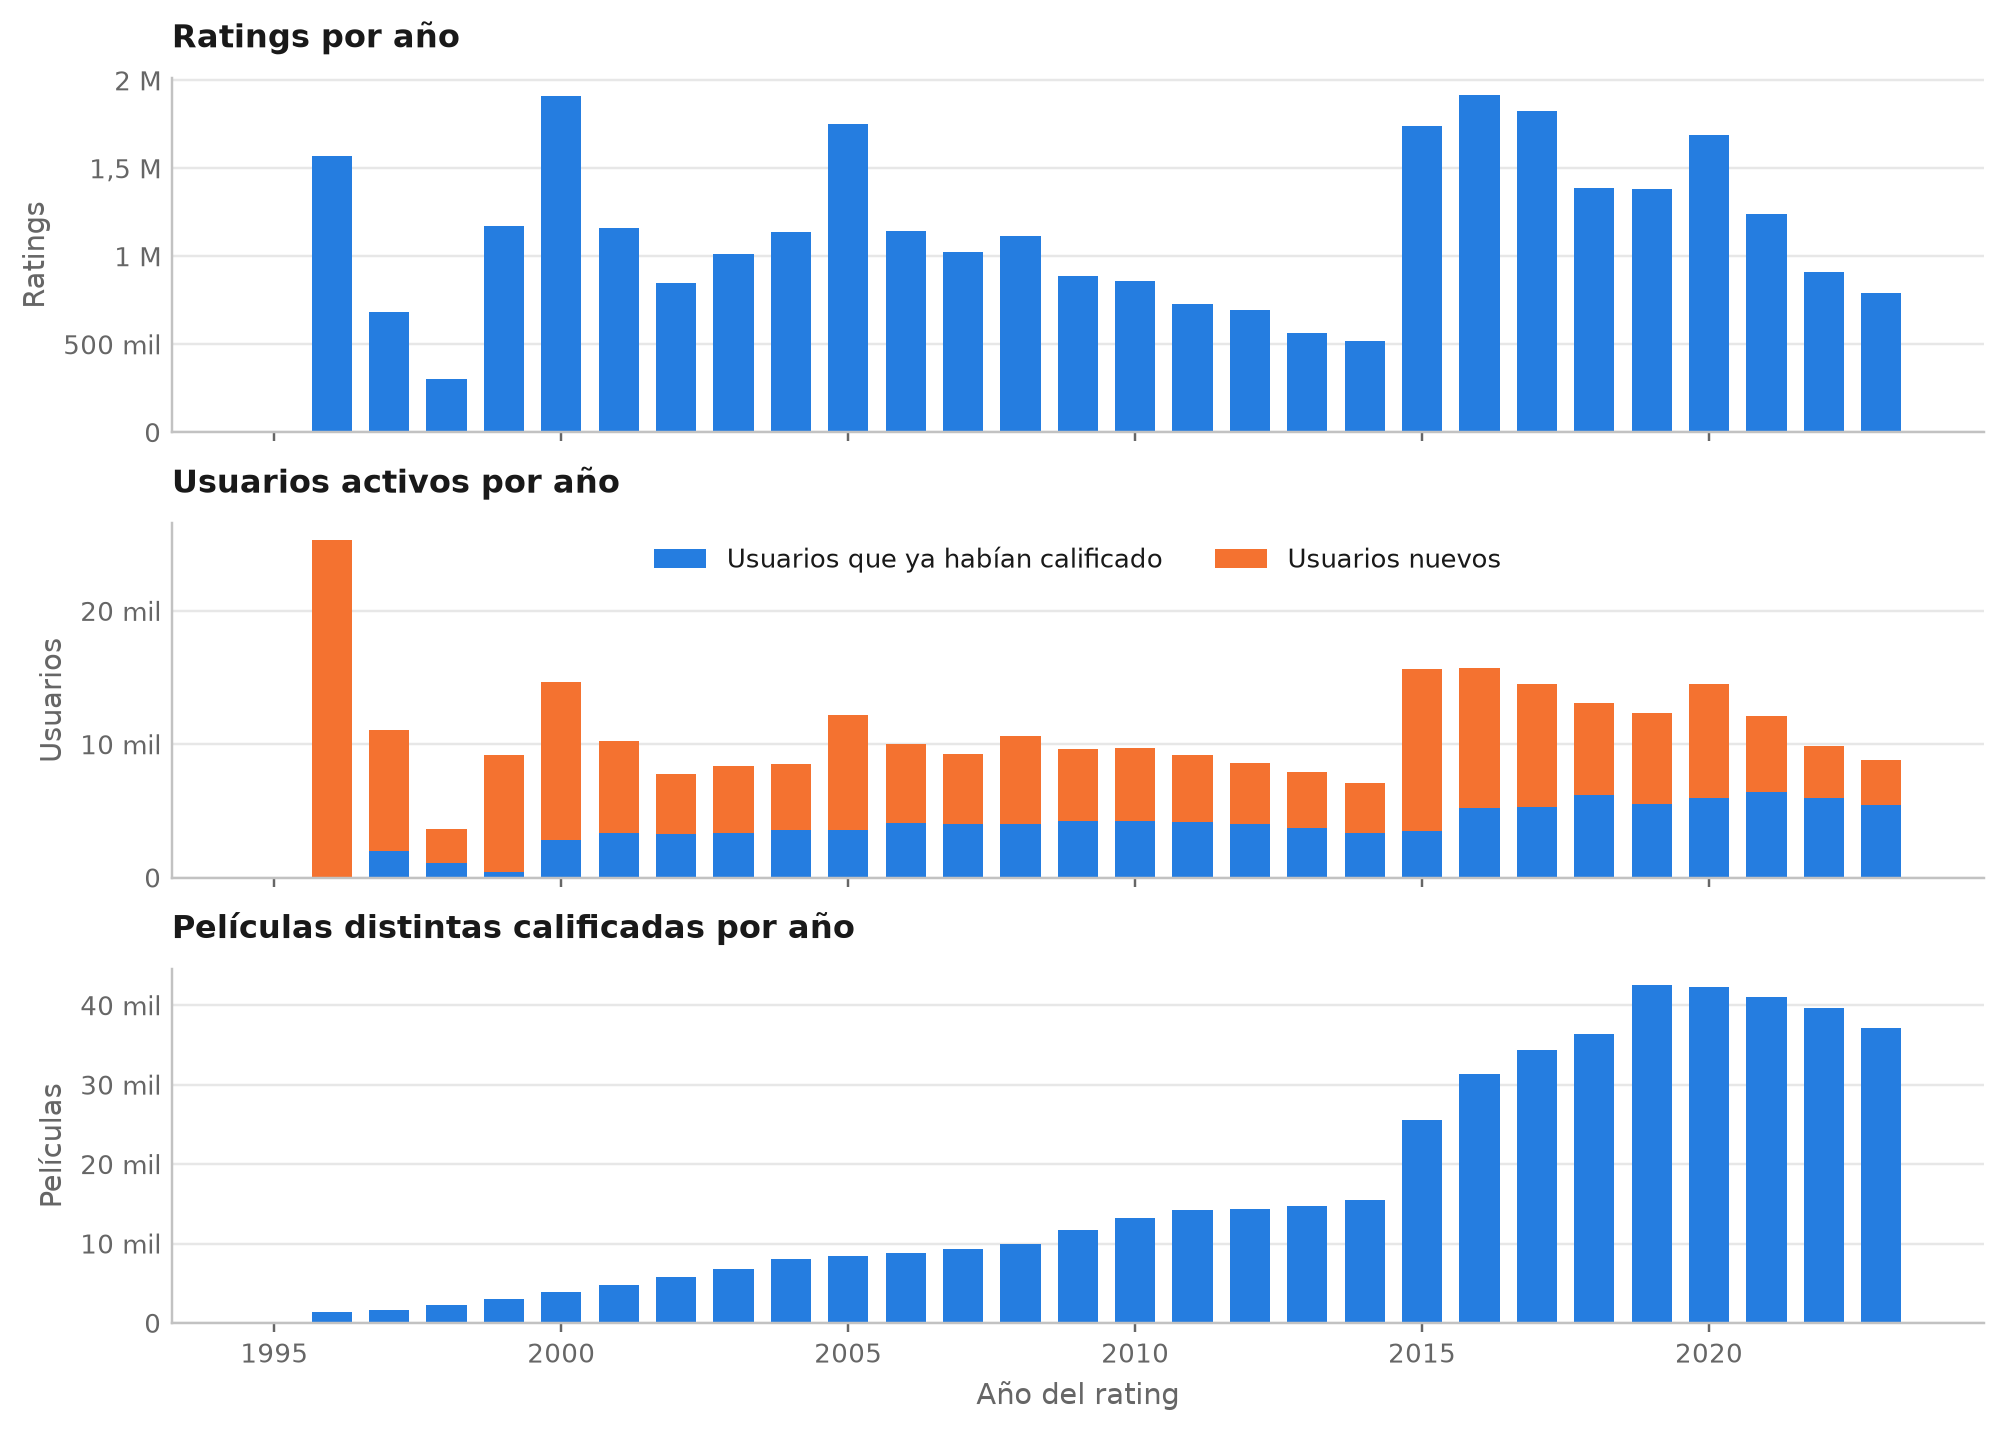

In [11]:
yearly = eda.yearly_activity(validated)
R.fig_yearly_activity(yearly)

**Figura 7.** Actividad por año del rating. Arriba, el volumen de ratings. Al centro, los usuarios activos, separados entre usuarios nuevos (primer rating ese año) y usuarios que ya habían calificado antes. Abajo, el número de películas distintas calificadas en el año.

**Lectura.** La actividad llega en olas: 1996, cuando todos los usuarios son nuevos; 1999-2000; 2005; y 2015-2016. Cada ola coincide con una llegada masiva de usuarios nuevos. La retención es baja: en ningún año los usuarios que vuelven superan los 7.000. La amplitud del catálogo calificado crece de forma sostenida, de 1.386 películas en 1996 a más de 42.000 en 2019. **Implicancia:** una partición temporal de entrenamiento y prueba (por ejemplo, los últimos años como prueba) es más realista que una aleatoria, y tendrá muchos usuarios en arranque en frío.

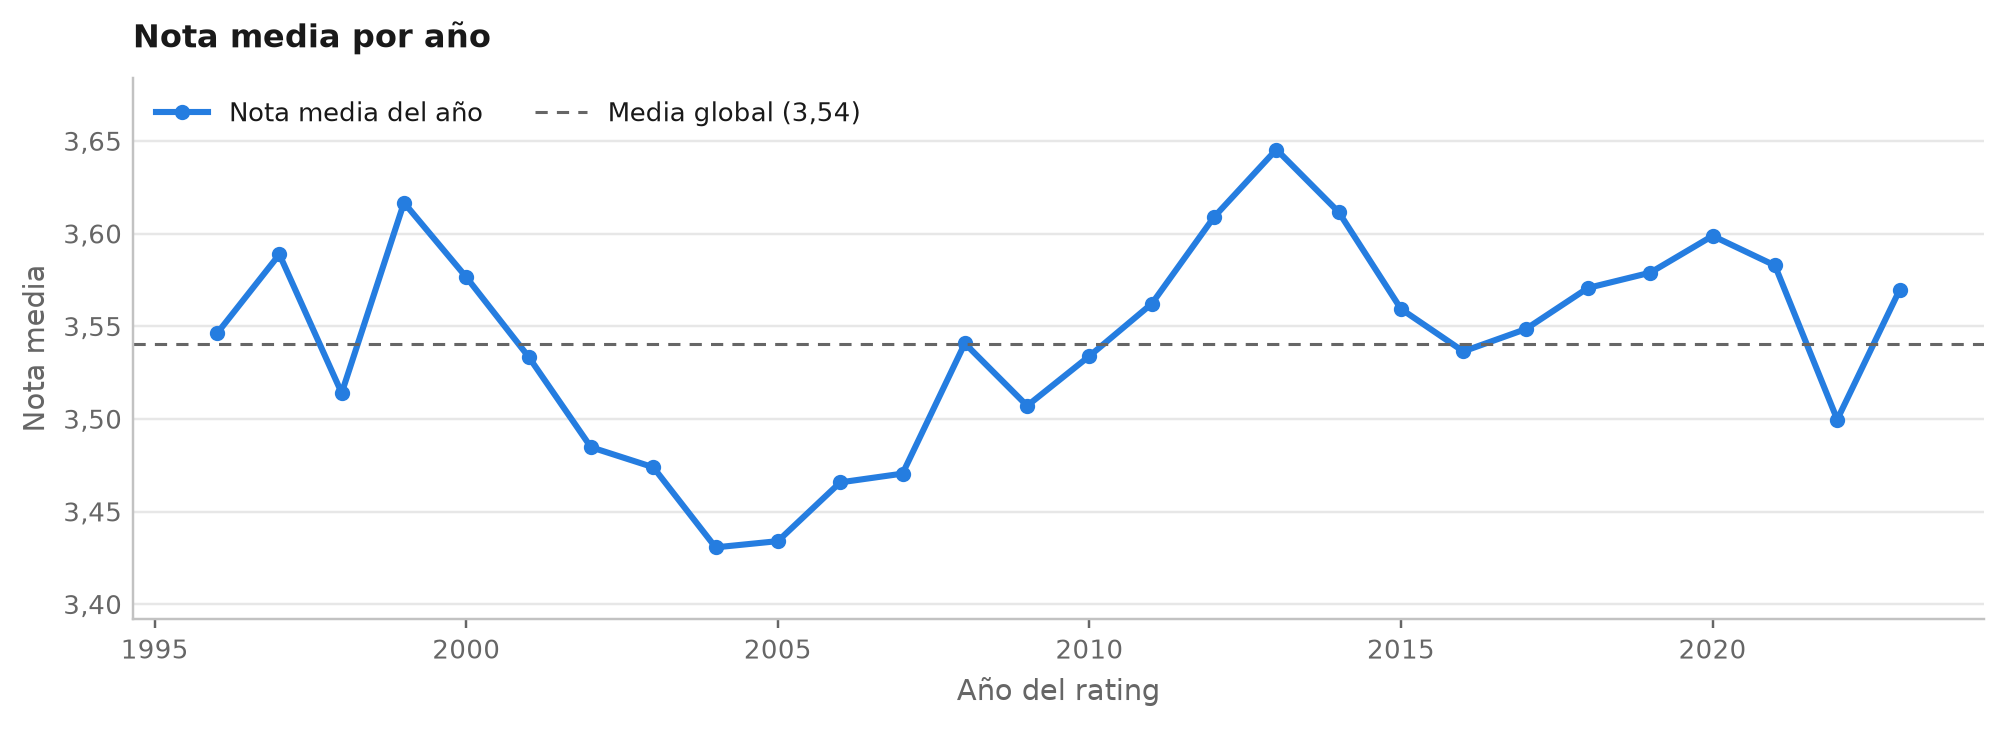

In [12]:
R.fig_yearly_mean(yearly, kv['mean_rating'])

**Figura 8.** Nota media de los ratings emitidos cada año. Se excluye 1995, que tiene solo 4 ratings. Los intervalos de confianza al 95% miden menos de ±0,01 en todos los años, por lo que no se dibujan.

**Lectura.** La nota media varía entre 3,43 (2004) y 3,65 (2013). Las diferencias son estadísticamente significativas pero pequeñas en la práctica, de unas ±0,1 estrellas alrededor de la media global. El mínimo de 2004-2005 coincide con los primeros años de las medias estrellas (Figura 2), aunque el descenso empieza antes, en 2001.

## 5. Contenido: géneros y década de estreno

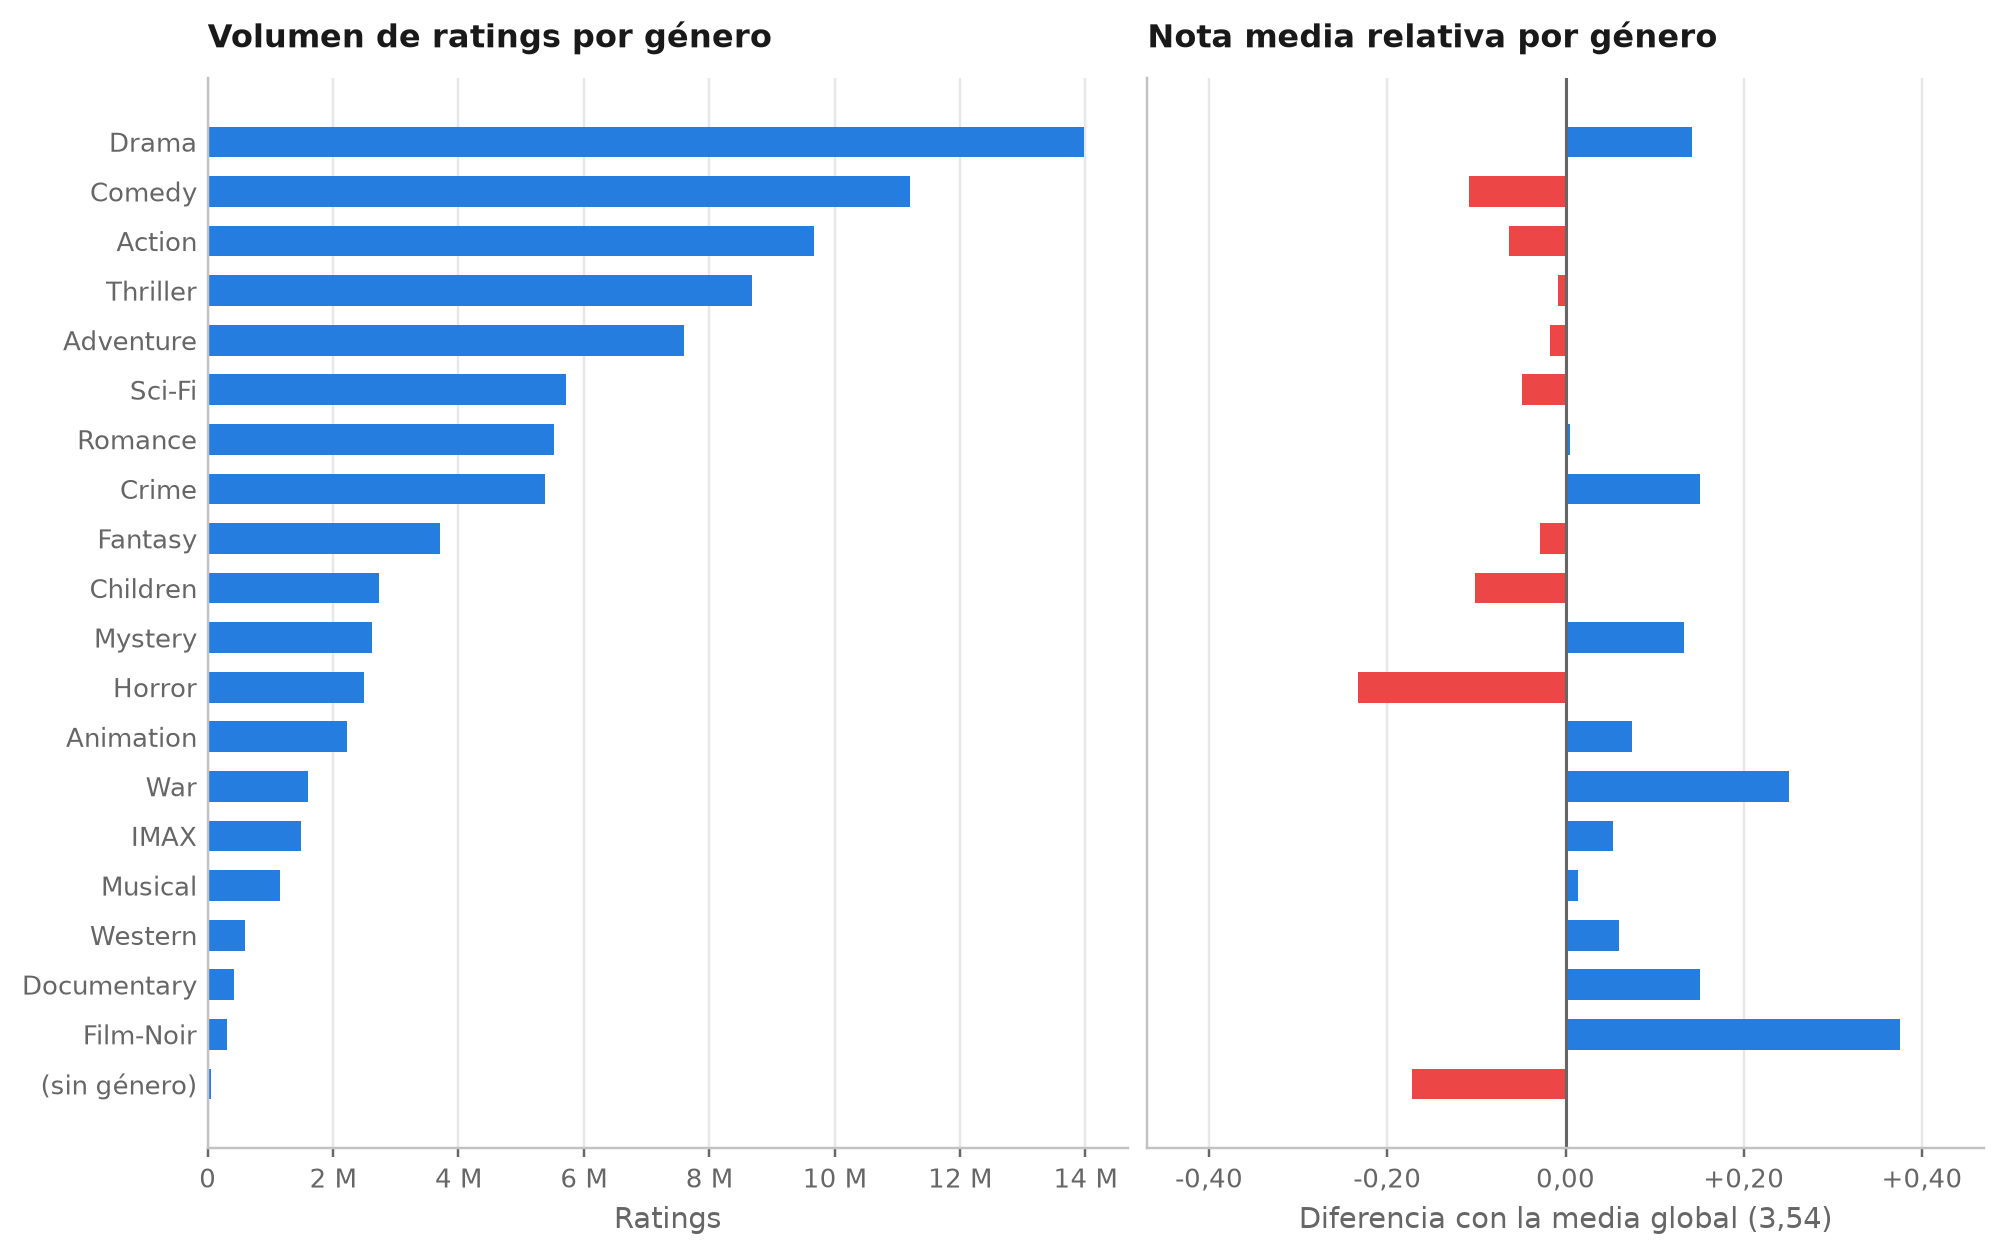

In [13]:
genres = eda.genre_stats(validated)
R.fig_genres(genres, kv['mean_rating'])

**Figura 9.** A la izquierda, el número de ratings por género. A la derecha, la diferencia entre la nota media del género y la media global, en azul si está por encima y en rojo si está por debajo. Una película puede tener varios géneros, por lo que la suma supera el total de ratings.

**Lectura.** Drama, Comedy y Action concentran el volumen. Por nota, destacan Film-Noir (+0,38), War (+0,25) y Crime, Documentary y Drama (≈ +0,15), mientras que Horror (−0,23), las películas sin género (−0,17), Comedy y Children (≈ −0,10) quedan bajo la media. Con millones de ratings por género, los intervalos de confianza son menores que ±0,01.

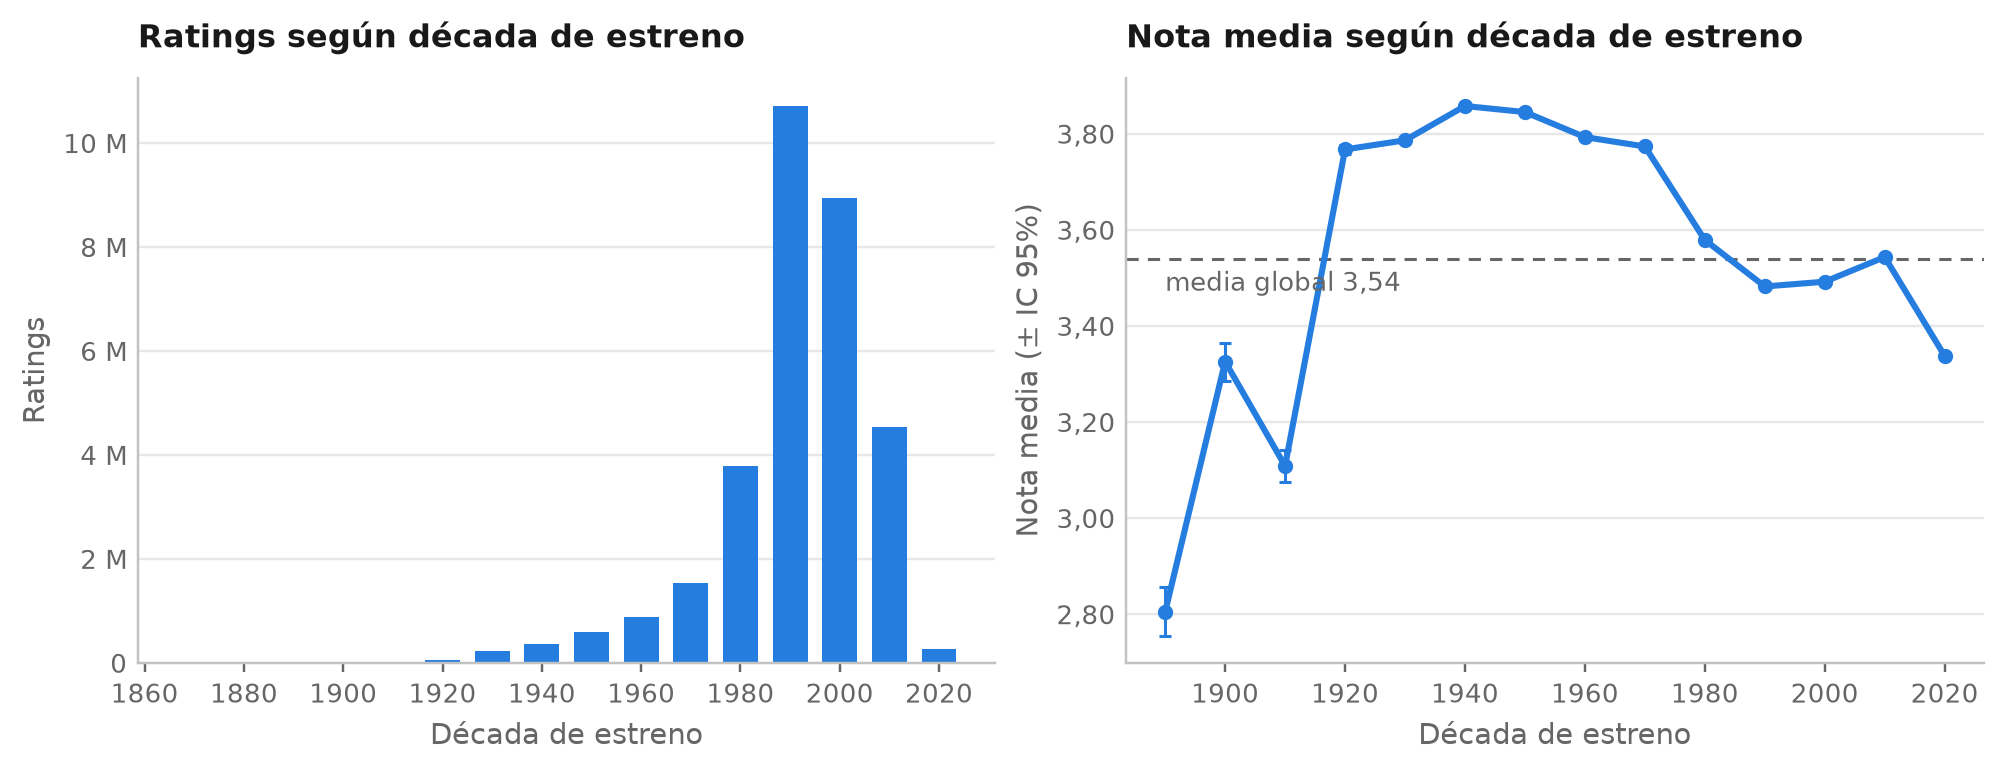

In [14]:
decades = eda.release_decade_stats(validated)
R.fig_release_decades(decades, kv['mean_rating'])

**Figura 10.** Ratings y nota media según la década de estreno, que se obtiene del año entre paréntesis al final del título. Quedan fuera 617 películas sin año. En el panel derecho solo se muestran las décadas con al menos 1.000 ratings, con su IC 95%.

**Lectura.** Las películas de los años 90 reciben el 33,5% de los ratings. Las películas de 1920 a 1979 promedian entre 3,77 y 3,86, bastante por encima de las de 1990 en adelante (entre 3,34 y 3,54). Es un **sesgo de supervivencia**: de las décadas antiguas solo se siguen viendo los clásicos, mientras que de las recientes se ve de todo.

## 6. Dispersión de la matriz y efecto del k-core

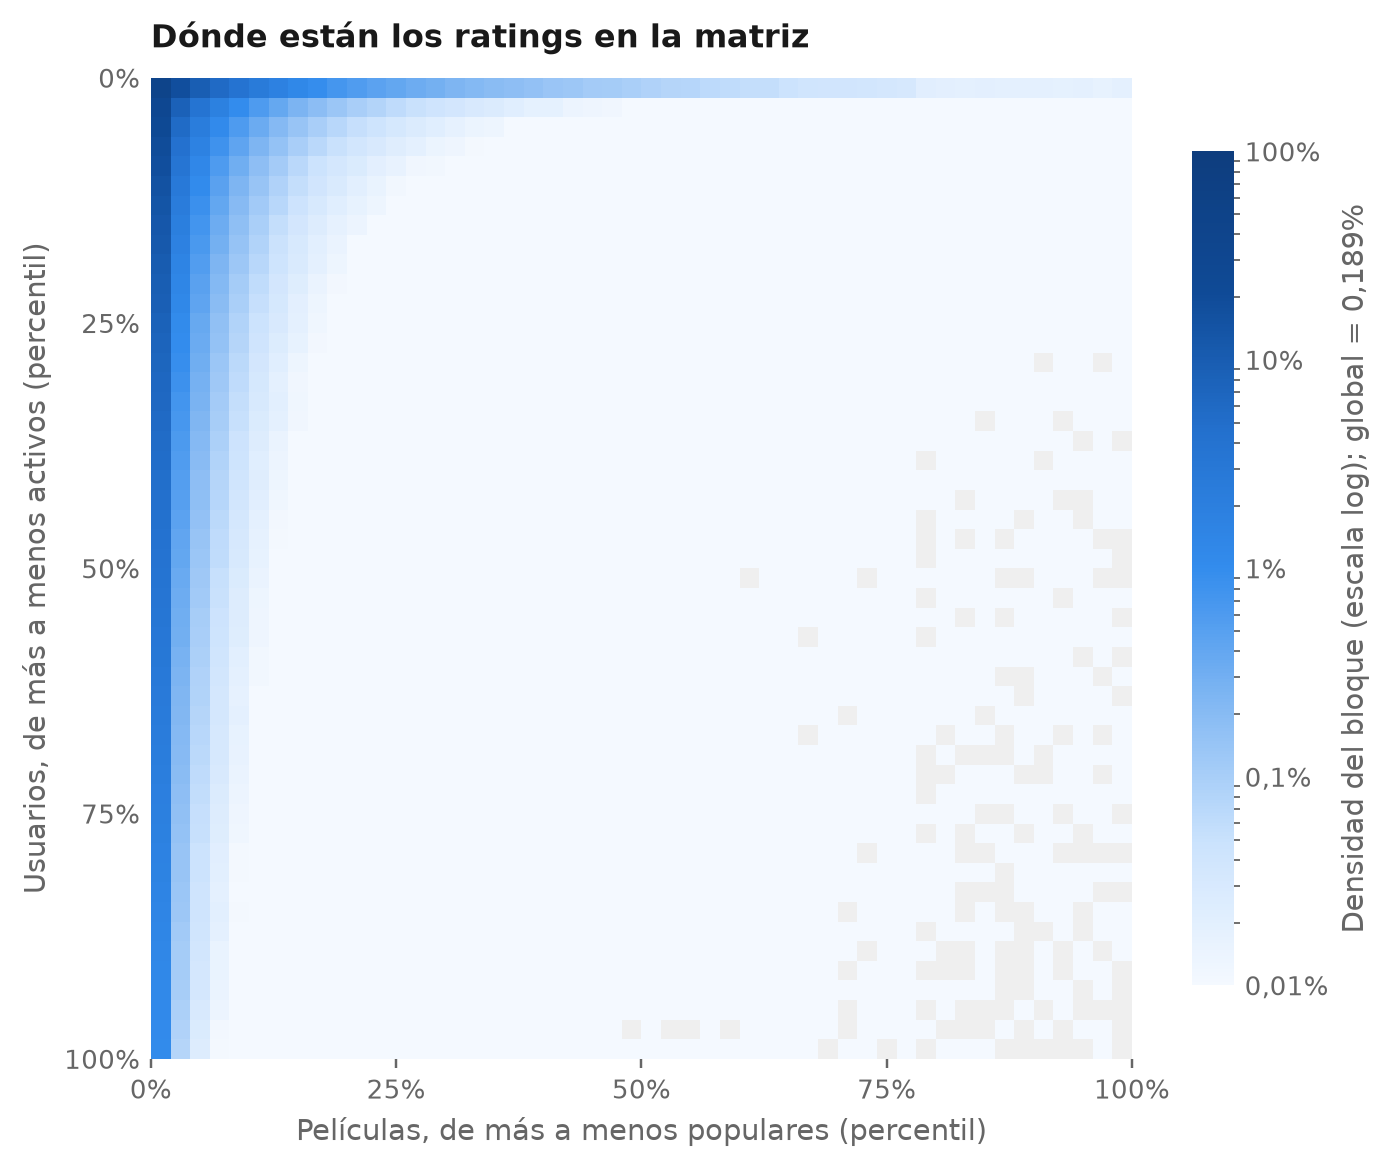

In [15]:
R.fig_sparsity_blocks(eda.sparsity_blocks(validated, bins=50), kv['density_pct'])

**Figura 11.** Densidad de la matriz usuario × película por bloques. Los usuarios se ordenan de más a menos activos y las películas de más a menos populares. Cada eje se divide en 50 grupos de igual tamaño (2% cada uno). El color, en escala logarítmica, indica qué porcentaje de las celdas del bloque tiene un rating. Los bloques grises no tienen ningún rating.

**Lectura.** La densidad global es del 0,189%, pero está muy desigualmente repartida. El bloque de los usuarios más activos y las películas más populares llega al 43,5%, y el 83% de los bloques está por debajo del 0,01%. La mitad menos popular del catálogo tiene como máximo 5 ratings por película y reúne solo el 0,27% de los ratings. **Implicancia:** las películas de la cola larga no aportan señal colaborativa suficiente. Esto justifica el k-core y, para esas películas, el uso de contenido (géneros, tags) en lugar de filtrado colaborativo.

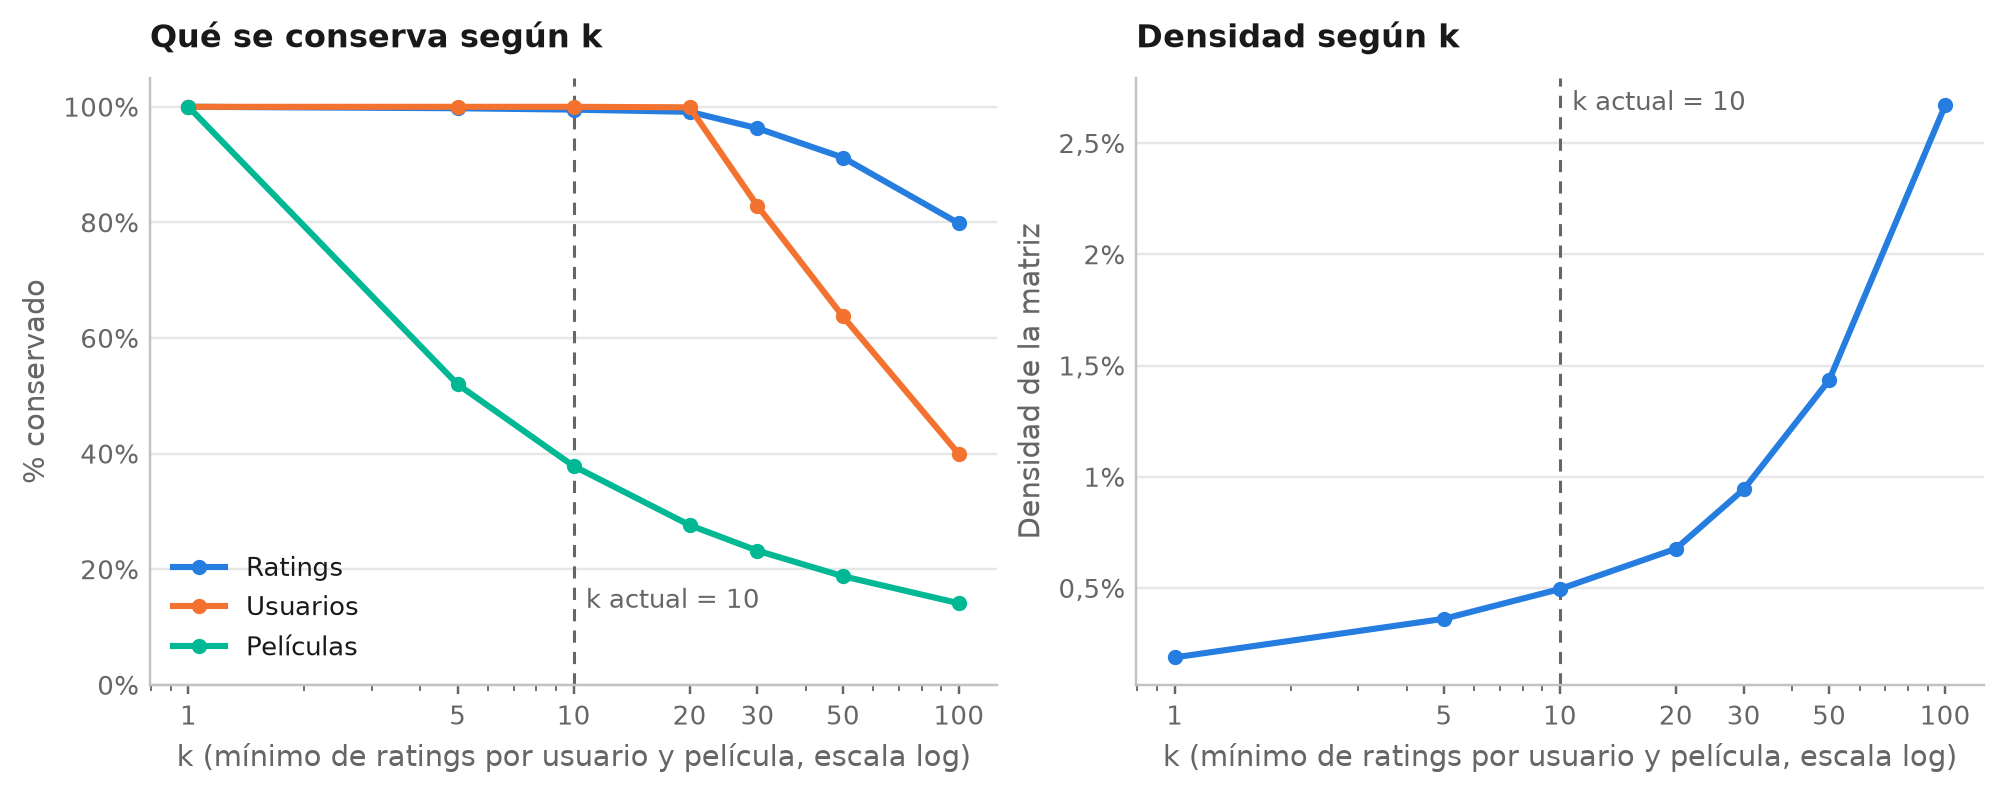

In [16]:
sweep = pd.read_csv(KCORE_SWEEP)
R.fig_kcore_sensitivity(sweep, K)

**Figura 12.** Sensibilidad del k-core al umbral k, con el mismo k para usuarios y películas. A la izquierda, el porcentaje de ratings, usuarios y películas que se conserva. A la derecha, la densidad resultante. Los datos provienen de la etapa `profile` del pipeline.

In [17]:
t4 = pd.DataFrame({
    'k': sweep['k'],
    'Ratings': sweep['ratings'].map(eda.fmt_int),
    'Usuarios': sweep['users'].map(eda.fmt_int),
    'Películas': sweep['movies'].map(eda.fmt_int),
    'Ratings conservados': sweep['ratings_kept_pct'].map(eda.fmt_pct),
    'Usuarios conservados': sweep['users_kept_pct'].map(eda.fmt_pct),
    'Películas conservadas': sweep['movies_kept_pct'].map(eda.fmt_pct),
    'Densidad': sweep['density_pct'].map(lambda v: eda.fmt_pct(v, 3)),
    'Iteraciones': sweep['iterations'],
})
R.table(t4, 'Tabla 4. Resultado del k-core para cada k evaluado')

k,Ratings,Usuarios,Películas,Ratings conservados,Usuarios conservados,Películas conservadas,Densidad,Iteraciones
1,32.000.204,200.948,84.432,"100,0%","100,0%","100,0%","0,189%",1
5,31.921.467,200.948,43.884,"99,8%","100,0%","52,0%","0,362%",2
10,31.842.696,200.947,31.961,"99,5%","100,0%","37,9%","0,496%",3
20,31.722.400,200.763,23.339,"99,1%","99,9%","27,6%","0,677%",4
30,30.813.560,166.510,19.607,"96,3%","82,9%","23,2%","0,944%",5
50,29.191.222,128.075,15.883,"91,2%","63,7%","18,8%","1,435%",4
100,25.545.765,80.230,11.928,"79,8%","39,9%","14,1%","2,669%",6


**Lectura.** Hasta k = 20 casi no se pierden ratings (99,1%) ni usuarios (99,9%). El costo se concentra en las películas: con k = 10 se conserva el 37,9% y con k = 20, el 27,6%. Desde k = 30 se empiezan a perder usuarios (17%) y con k = 100 se pierde el 60%. El valor vigente, **k = 10**, multiplica la densidad por 2,6 a cambio de solo el 0,5% de los ratings.

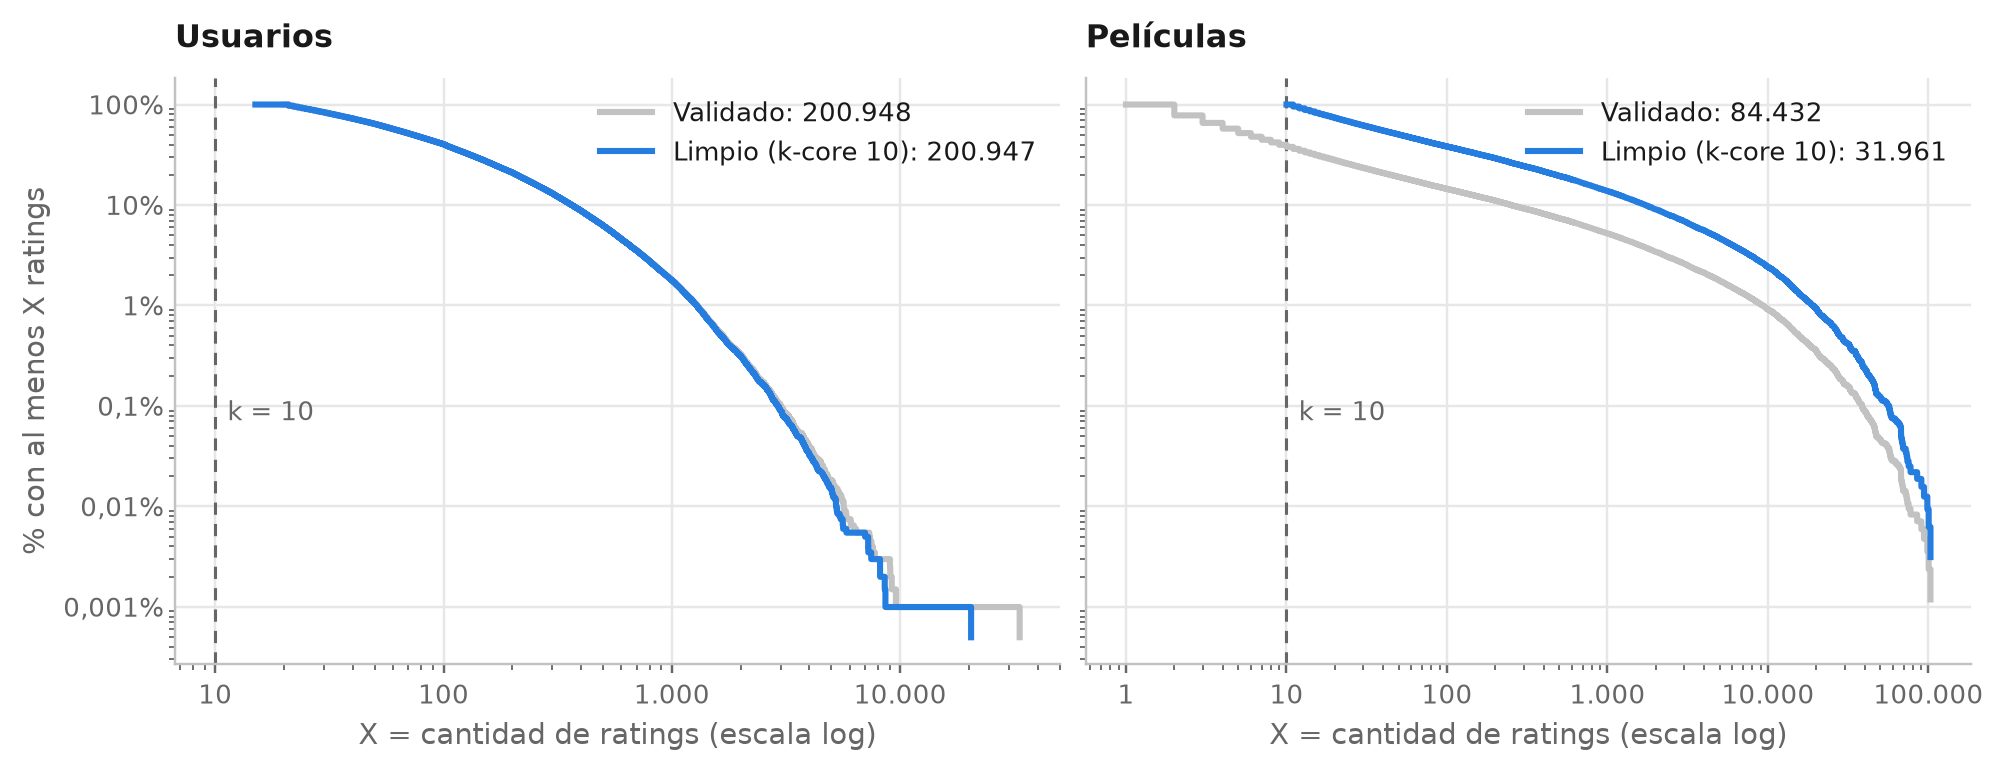

In [18]:
R.fig_kcore_effect({'users': users['n'], 'movies': movies['n']},
                   {'users': users_c['n'], 'movies': movies_c['n']}, K)

In [19]:
def activity_row(name, s):
    q = s.quantile([0.1, 0.5, 0.9])
    return {'Grupo': name, 'Cantidad': eda.fmt_int(len(s)), 'Mínimo': eda.fmt_int(s.min()), 'P10': eda.fmt_int(q[0.1]),
            'Mediana': eda.fmt_int(q[0.5]), 'P90': eda.fmt_int(q[0.9]), 'Máximo': eda.fmt_int(s.max()),
            'Gini': eda.fmt_num(eda.gini(s))}

R.table(pd.DataFrame([activity_row('Usuarios · validado', users['n']), activity_row('Usuarios · limpio', users_c['n']),
                      activity_row('Películas · validado', movies['n']), activity_row('Películas · limpio', movies_c['n'])]),
        'Tabla 5. Ratings por usuario y por película antes y después del k-core')

Grupo,Cantidad,Mínimo,P10,Mediana,P90,Máximo,Gini
Usuarios · validado,200.948,20,25,73,364,33.332,"0,59"
Usuarios · limpio,200.947,15,25,73,363,20.432,"0,59"
Películas · validado,84.432,1,1,5,249,102.929,"0,95"
Películas · limpio,31.961,10,12,50,1.720,102.929,"0,89"


**Figura 13 y Tabla 5.** Distribución de la actividad antes (gris) y después (azul) del k-core, en escala log-log.

**Lectura.** En los usuarios el k-core casi no cambia nada: la curva limpia se superpone a la validada y solo se elimina un usuario. En las películas elimina toda la cola de menos de 10 ratings: la mediana pasa de 5 a 50 ratings por película y el Gini baja de 0,95 a 0,89. El mínimo de los usuarios limpios (15) es menor que su mínimo original (20) porque el k-core también elimina ratings de películas descartadas, aunque siempre respeta k.

## 7. Conclusiones e implicancias para el modelado

| # | Hallazgo | Evidencia | Implicancia |
|---|---|---|---|
| 1 | Los datos pasan todos los controles de calidad | Tabla 2 | Se puede entrenar sobre `data/processed` sin limpieza adicional |
| 2 | La escala es de 0,5 a 5,0, con medias estrellas desde 2003 | Figuras 1 y 2 | Validar 0,5–5,0 (D-01, pendiente con el PO) y tratar la nota como continua |
| 3 | Hay sesgos fuertes por usuario y por película | Figuras 3 y 6 | Usar *baselines* con sesgos y medias contraídas como referencia mínima |
| 4 | La popularidad está muy concentrada (Gini 0,95) | Figuras 4 y 5 | Medir cobertura y novedad además de precisión |
| 5 | La actividad llega en olas y la retención es baja | Figura 7 | Evaluar con una partición temporal y planificar el arranque en frío |
| 6 | Las décadas antiguas tienen notas infladas por supervivencia | Figura 10 | No usar el año de estreno como señal de calidad sin corregir ese sesgo |
| 7 | La densidad es del 0,19% y está concentrada | Figura 11 | El filtrado colaborativo no sirve para la cola larga; complementar con contenido |
| 8 | k = 10 cuesta el 0,5% de los ratings y el 62% del catálogo | Figuras 12 y 13, Tabla 4 | Acordar con el PO si el producto debe recomendar películas de la cola larga |

## 8. Limitaciones
- El análisis es descriptivo: las asociaciones observadas, como entre popularidad y nota o entre década y nota, no implican causalidad.
- Los géneros vienen del catálogo de MovieLens y pueden ser incompletos. 617 películas no tienen año en el título.
- No se analizan los tags ni los enlaces externos. Quedan para una historia posterior si el modelo usa contenido.
- Las cifras del texto son las de la ejecución indicada al inicio. Si cambia `params.yaml`, las figuras se actualizan, pero el texto no.

## 9. Anexo: reproducibilidad

In [20]:
import importlib.metadata as md_
print('Parámetros vigentes (params.yaml):')
print(yaml.safe_dump({k: params[k] for k in ('validation', 'clean')}, allow_unicode=True, sort_keys=False))
print('Paquetes:', ', '.join(f'{p} {md_.version(p)}' for p in ('pandas', 'numpy', 'duckdb', 'matplotlib', 'dvc')))
print('Datos limpios (dvc.lock):', data_hash)

Parámetros vigentes (params.yaml):
validation:
  verify_checksums: true
  rating_min: 0.5
  rating_max: 5.0
  rating_step: 0.5
  min_date: '1995-01-01'
  severity_overrides: {}
clean:
  iterative: true
  max_iter: 50

Paquetes: pandas 3.1.1, numpy 2.5.5, duckdb 1.5.6, matplotlib 3.11.2, dvc 3.67.1
Datos limpios (dvc.lock): 40e3a792e5ae8f68a817a2d09d75a54d.dir
